In [1]:
import sys, os
sys.path.insert(0, os.path.abspath('../code'))
import numpy as np
import matplotlib.pyplot as plt
import muography as mg
import project_config as cfg
import student_analysis as sa
print('ready')


ready


## Poisson counting

If the expected number of events is N, the typical statistical spread is about √N. Use the fixed reference seed while developing so that your noisy figures are reproducible.


In [2]:
rng = np.random.default_rng(cfg.REFERENCE_SEED)
for mean in [10, 100, 1000, 10000]:
    draws = rng.poisson(mean, size=5000)
    print(f'expect {mean:6d}   actual spread = {draws.std():8.1f}   '
          f'(sqrt of mean = {np.sqrt(mean):8.1f})   relative = {draws.std()/mean:6.2%}')


expect     10   actual spread =      3.2   (sqrt of mean =      3.2)   relative = 32.15%
expect    100   actual spread =      9.9   (sqrt of mean =     10.0)   relative =  9.95%
expect   1000   actual spread =     31.7   (sqrt of mean =     31.6)   relative =  3.17%
expect  10000   actual spread =    100.9   (sqrt of mean =    100.0)   relative =  1.01%


## Build the baseline expectation maps

This notebook deliberately rebuilds its inputs from the shared functions. You can run it from a fresh kernel without running notebook 03 first.


In [3]:
target = mg.Pyramid(
    base=cfg.PYRAMID_BASE_M, height=cfg.PYRAMID_HEIGHT_M,
    density=cfg.ROCK_DENSITY_G_CM3, void_centre=cfg.VOID_CENTRE_M,
    void_radius=cfg.VOID_RADIUS_M, has_void=True,
)
target0 = target.without_void()
detector = np.array(cfg.DETECTOR_POSITION_M, dtype=float)

# trace each target once. Thirty days is just thirty times the expected counts.
expected_1d, ax_deg, ay_deg = sa.expected_counts(target, detector, 1.0)
expected_1d_0, _, _ = sa.expected_counts(target0, detector, 1.0)
expected_30d = expected_1d * 30
expected_30d_0 = expected_1d_0 * 30
signal_idx = sa.signal_pixel(expected_1d, expected_1d_0)
half_bin = cfg.STEP_DEG / 2
extent = [ax_deg.min() - half_bin, ax_deg.max() + half_bin,
          ay_deg.min() - half_bin, ay_deg.max() + half_bin]

### YOUR TURN — make the images noisy

Use `mg.poisson_counts` with the reference seed to make 1-day and 30-day observed count maps. Plot each observed map divided by the corresponding **expected no-void** map.


In [4]:
# start the random generator here so Run All gives the same pair each time
rng = np.random.default_rng(cfg.REFERENCE_SEED)
observed_1d = mg.poisson_counts(expected_1d, rng)
observed_30d = mg.poisson_counts(expected_30d, rng)

In [5]:
# check the totals without taking another random draw
print("1 day:", observed_1d.sum(), "simulated muons")
print("30 days:", observed_30d.sum(), "simulated muons")

1 day: 32926 simulated muons
30 days: 984357 simulated muons


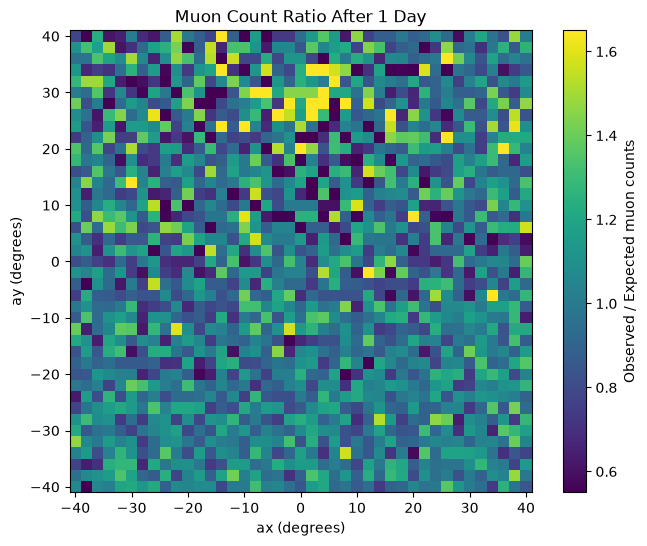

In [6]:
# compare noisy counts with the solid pyramid (1 day)
ratio_1d = sa.ratio_map(observed_1d, expected_1d_0)
plt.figure(figsize=(8, 6))

plt.imshow(ratio_1d, origin="lower",
           extent=extent,
           cmap="viridis", vmin=0.55, vmax=1.65)

plt.colorbar(label="Observed / Expected muon counts")

plt.xlabel("ax (degrees)")
plt.ylabel("ay (degrees)")
plt.title("Muon Count Ratio After 1 Day")

plt.show()

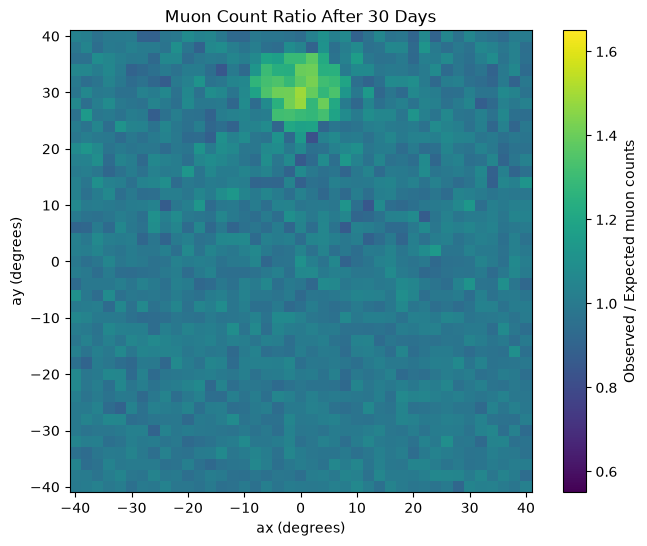

In [7]:
# compare noisy counts with the solid pyramid (30 days)
ratio_30d = sa.ratio_map(observed_30d, expected_30d_0)
plt.figure(figsize=(8, 6))

plt.imshow(ratio_30d, origin="lower",
           extent=extent,
           cmap="viridis", vmin=0.55, vmax=1.65)

plt.colorbar(label="Observed / Expected muon counts")

plt.xlabel("ax (degrees)")
plt.ylabel("ay (degrees)")
plt.title("Muon Count Ratio After 30 Days")

plt.show()

After 1 day, the ratio map is still dominated by Poisson noise, so the hidden chamber is difficult to identify clearly. After 30 days, the noise is reduced and a localized excess appears near the chamber position, showing that longer exposure improves detectability.

## Observed significance

`mg.significance(observed, expected_no_void)` compares one noisy observation with the no-chamber expectation. It fluctuates from run to run. For this educational project, 5σ is a predefined headline threshold; it is not a complete discovery test for a real experiment.

### YOUR TURN

Make significance maps for 1 day and 30 days. Record the random seed in your figure caption or log. Do not define the official exposure time from the largest noisy pixel.


In [8]:
S1_obs = mg.significance(observed_1d, expected_1d_0)
S30_obs = mg.significance(observed_30d, expected_30d_0)

# the brightest random pixel and our chosen chamber pixel can be different
print(f"1 day: max {S1_obs.max():.2f}σ, chosen pixel {S1_obs[signal_idx]:.2f}σ")
print(f"30 days: max {S30_obs.max():.2f}σ, chosen pixel {S30_obs[signal_idx]:.2f}σ")

1 day: max 4.07σ, chosen pixel 1.29σ
30 days: max 7.70σ, chosen pixel 7.70σ


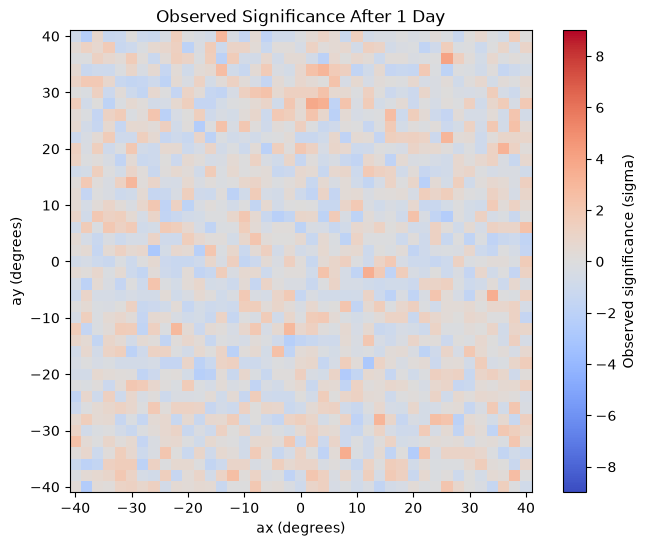

In [9]:
# 1-day observation significance

plt.figure(figsize=(8, 6))

plt.imshow(S1_obs, origin="lower",extent=extent, cmap="coolwarm", vmin=-9, vmax=9)

plt.colorbar(label="Observed significance (sigma)")

plt.xlabel("ax (degrees)")
plt.ylabel("ay (degrees)")
plt.title("Observed Significance After 1 Day")

plt.show()

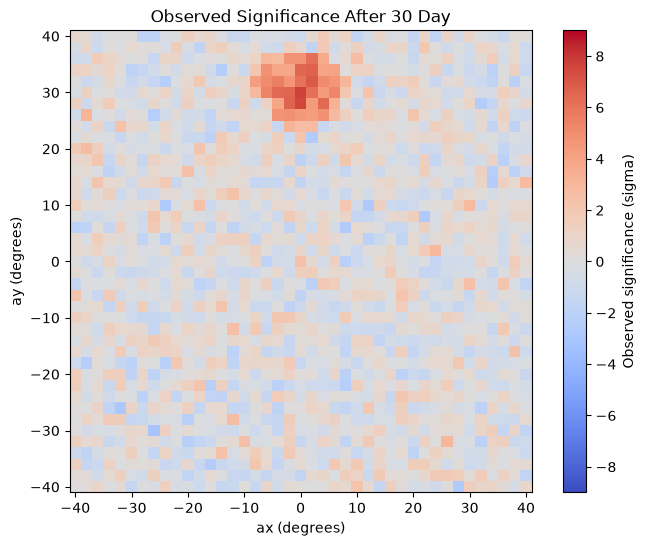

In [10]:
# 30-day observation significance

plt.figure(figsize=(8, 6))

plt.imshow(S30_obs, origin="lower",extent=extent, cmap="coolwarm", vmin=-9, vmax=9)

plt.colorbar(label="Observed significance (sigma)")

plt.xlabel("ax (degrees)")
plt.ylabel("ay (degrees)")
plt.title("Observed Significance After 30 Day")

plt.show()

## The main result: expected significance

The official headline curve uses **expected significance**:

`S_expected = (expected_with_void - expected_without_void) / sqrt(expected_without_void)`

This is deterministic for fixed parameters and follows the expected `√T` scaling. It is the correct quantity for a reproducible exposure-time estimate in this simplified project.


In [11]:
days_list = np.array([1, 2, 3, 5, 7, 10, 14, 21, 30, 45, 60, 90, 120, 180], dtype=float)

# both counts grow with time, but the noise term grows with sqrt(time)
S1_expected = mg.expected_significance(expected_1d, expected_1d_0)[signal_idx]
S_expected = S1_expected * np.sqrt(days_list)
t3 = sa.first_crossing(days_list, S_expected, 3)
crossing_time = sa.first_crossing(days_list, S_expected, 5)
t5_exact = (5 / S1_expected)**2

print(f"Signal pixel: ax={ax_deg[signal_idx]:.0f}°, ay={ay_deg[signal_idx]:.0f}°")
for d, s in zip(days_list, S_expected):
    print(f"{d:6.0f} days  expected S = {s:6.3f}")

Signal pixel: ax=0°, ay=30°
     1 days  expected S =  1.370
     2 days  expected S =  1.937
     3 days  expected S =  2.372
     5 days  expected S =  3.062
     7 days  expected S =  3.624
    10 days  expected S =  4.331
    14 days  expected S =  5.125
    21 days  expected S =  6.276
    30 days  expected S =  7.502
    45 days  expected S =  9.187
    60 days  expected S = 10.609
    90 days  expected S = 12.993
   120 days  expected S = 15.003
   180 days  expected S = 18.375


### YOUR TURN — plot the exposure curve

Plot `S_expected` against days on a logarithmic x-axis. Add horizontal lines at 3σ and 5σ. Determine the first crossing of 5σ by interpolation between the nearest scan points.

Your headline sentence should be:

> **For the baseline 0.25 m² detector and 10 m radius chamber, the expected signal reaches 5σ after approximately ___ days under the project's simplified model.**

Do not add an uncertainty to this number unless your mentor gives you a defined procedure for estimating one.


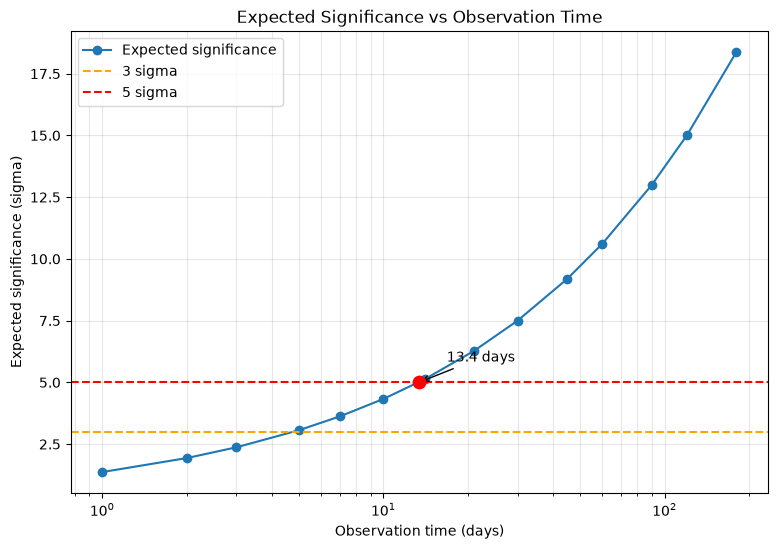

In [12]:
# how significance changes the longer we collect muons

plt.figure(figsize=(9, 6))

# plot expected significance against time in log scale

plt.plot(days_list, S_expected, marker="o", label="Expected significance")
plt.xscale("log")

plt.axhline(3, color="orange", linestyle="--", label="3 sigma")
plt.axhline(5, color="red", linestyle="--", label="5 sigma")

plt.xlabel("Observation time (days)")
plt.ylabel("Expected significance (sigma)")
plt.title("Expected Significance vs Observation Time")

plt.legend()
plt.grid(True, which="both", alpha=0.3)

# use the crossing we got from the two points around 5 sigma
# mark where it hits 5 sigma
plt.scatter(crossing_time, 5, color="red", s=80, zorder=5)

plt.annotate(f"{crossing_time:.1f} days",
             (crossing_time, 5),
             xytext=(20, 15),
             textcoords="offset points",
             arrowprops=dict(arrowstyle="->"))
plt.show()

In [13]:
print(f"Expected 3 sigma crossing: {t3:.2f} days")
print(f"Expected 5 sigma crossing: {crossing_time:.2f} days (interpolated)")
print(f"Square-root formula check: {t5_exact:.2f} days")

Expected 3 sigma crossing: 4.82 days
Expected 5 sigma crossing: 13.37 days (interpolated)
Square-root formula check: 13.33 days


For the baseline 0.25 m² detector and 10 m radius chamber, the expected signal reaches 5σ after approximately 13.4 days under the project's simplified model.

## Why the noisy curve is different

If you repeat the analysis with Poisson observations, individual significance values will jitter around the expected curve. That is not a bug. It is the statistical fluctuation the simulation is designed to teach.

The previous version of this project used the maximum noisy pixel as the headline statistic. We no longer do that: choosing a pixel because it fluctuated upward introduces a selection bias. You may explore the maximum as a separate exercise, but it is not the official exposure-time definition.


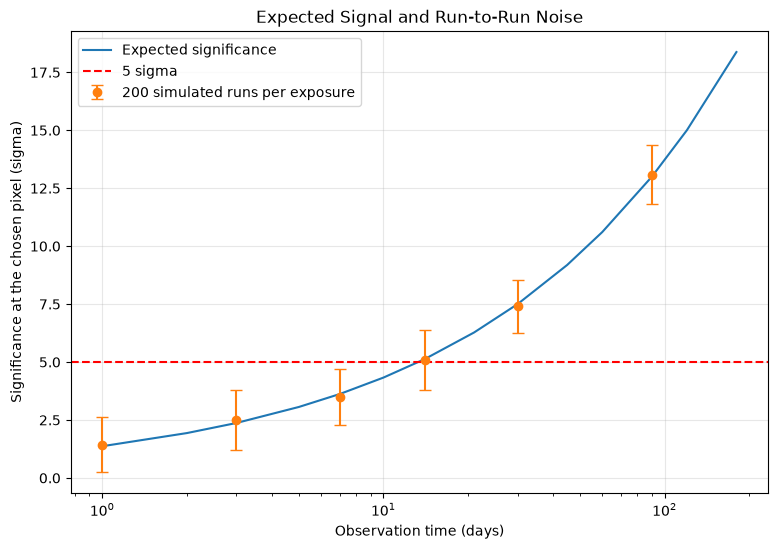

In [14]:
# take 200 fresh samples at each exposure and compare the spread with the curve
obs_days = [1, 3, 7, 14, 30, 90]
rng_exposure = np.random.default_rng(cfg.REFERENCE_SEED)
obs_mean = []
obs_std = []

for days in obs_days:
    values = []
    for _ in range(200):
        counts = mg.poisson_counts(expected_1d * days, rng_exposure)
        values.append(mg.significance(counts, expected_1d_0 * days)[signal_idx])
    obs_mean.append(np.mean(values))
    obs_std.append(np.std(values))

plt.figure(figsize=(9, 6))
plt.plot(days_list, S_expected, label="Expected significance")
plt.errorbar(obs_days, obs_mean, yerr=obs_std, fmt="o", capsize=4,
             label="200 simulated runs per exposure")
plt.axhline(5, color="red", linestyle="--", label="5 sigma")
plt.xscale("log")
plt.xlabel("Observation time (days)")
plt.ylabel("Significance at the chosen pixel (sigma)")
plt.title("Expected Signal and Run-to-Run Noise")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## Optional: the no-void control

Run the same noisy significance calculation on `target.without_void()`. This gives you a concrete demonstration that a noise-only image can contain locally surprising pixels. In your report, call this a **control** or **null simulation**, not a discovery test.


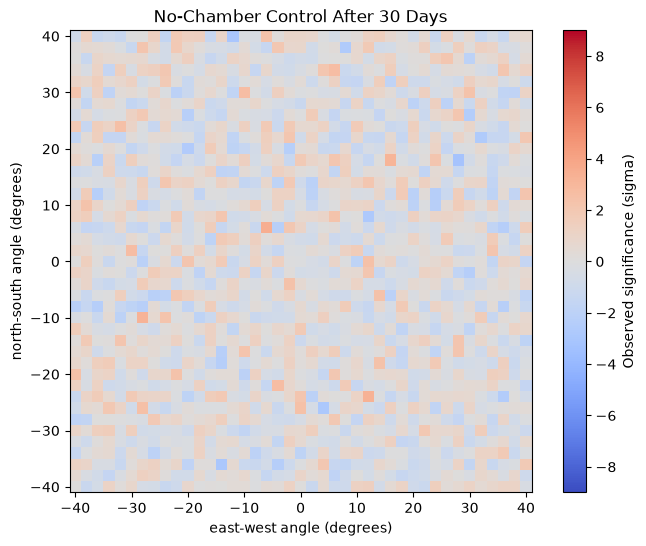

In [15]:
# No chamber (Null simulation)

# simulate 30 days of muons through a solid pyramid
rng_control = np.random.default_rng(cfg.REFERENCE_SEED + 1)

observed_control = mg.poisson_counts(expected_30d_0, rng_control)
S_control = mg.significance(observed_control, expected_30d_0)

plt.figure(figsize=(8, 6))

plt.imshow(S_control, origin="lower",
           extent=extent,
           cmap="coolwarm", vmin=-9, vmax=9)

plt.colorbar(label="Observed significance (sigma)")

plt.xlabel("east-west angle (degrees)")
plt.ylabel("north-south angle (degrees)")
plt.title("No-Chamber Control After 30 Days")

plt.show()

Max pixel above 3 sigma: 91.6%
Max pixel above 5 sigma: 0.0%


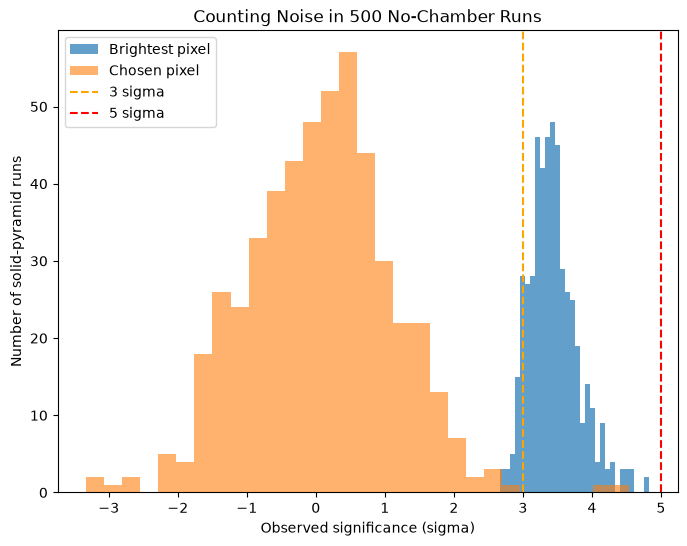

In [16]:
# repeat the solid-pyramid check to see how often noise gives us a bright pixel
rng_null = np.random.default_rng(cfg.REFERENCE_SEED + 1)
null_max = []
null_at_signal = []

for _ in range(500):
    counts = mg.poisson_counts(expected_30d_0, rng_null)
    S_null = mg.significance(counts, expected_30d_0)
    null_max.append(S_null.max())
    null_at_signal.append(S_null[signal_idx])

null_max = np.array(null_max)
print(f"Max pixel above 3 sigma: {np.mean(null_max > 3):.1%}")
print(f"Max pixel above 5 sigma: {np.mean(null_max > 5):.1%}")

plt.figure(figsize=(8, 6))
plt.hist(null_max, bins=30, alpha=0.7, label="Brightest pixel")
plt.hist(null_at_signal, bins=30, alpha=0.6, label="Chosen pixel")
plt.axvline(3, color="orange", linestyle="--", label="3 sigma")
plt.axvline(5, color="red", linestyle="--", label="5 sigma")
plt.xlabel("Observed significance (sigma)")
plt.ylabel("Number of solid-pyramid runs")
plt.title("Counting Noise in 500 No-Chamber Runs")
plt.legend()
plt.show()

## How often does the chamber signal cross 5 sigma?

7 days: 15.2% of runs crossed 5 sigma
14 days: 54.0% of runs crossed 5 sigma
30 days: 98.0% of runs crossed 5 sigma


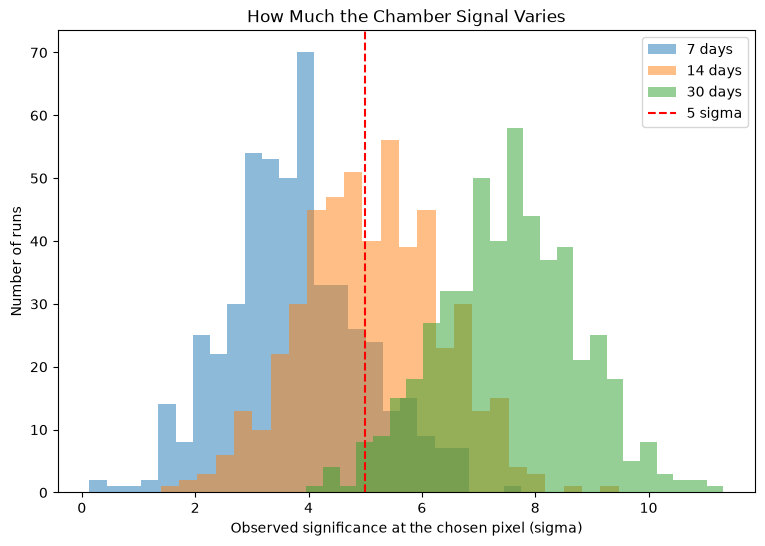

In [17]:
# a separate set of 500 runs to see the chance of crossing 5 sigma
rng_void = np.random.default_rng(cfg.REFERENCE_SEED + 2)
plt.figure(figsize=(9, 6))

for days in [7, 14, 30]:
    values = []
    for _ in range(500):
        counts = mg.poisson_counts(expected_1d * days, rng_void)
        values.append(mg.significance(counts, expected_1d_0 * days)[signal_idx])
    values = np.array(values)
    plt.hist(values, bins=25, alpha=0.5, label=f"{days} days")
    print(f"{days} days: {np.mean(values > 5):.1%} of runs crossed 5 sigma")

plt.axvline(5, color="red", linestyle="--", label="5 sigma")
plt.xlabel("Observed significance at the chosen pixel (sigma)")
plt.ylabel("Number of runs")
plt.title("How Much the Chamber Signal Varies")
plt.legend()
plt.show()

## One check on the angular bin size

In [18]:
# the same two-degree bin covers less sky when we tilt away from vertical
solid_angle_factor = sa.solid_angle_factor(ax_deg, ay_deg)
S1_corrected = mg.expected_significance(
    expected_1d * solid_angle_factor, expected_1d_0 * solid_angle_factor
)[signal_idx]
t5_corrected = (5 / S1_corrected)**2
print(f"Solid-angle factor at the chosen pixel: {solid_angle_factor[signal_idx]:.3f}")
print(f"5 sigma with the tangent-plane correction: {t5_corrected:.2f} days")

Solid-angle factor at the chosen pixel: 0.866
5 sigma with the tangent-plane correction: 15.39 days
